Loading dataset from: C:/Users/jrdie/OneDrive/Desktop/BTT/kidney_waitlist_analytic_opt.csv ...
Dataset loaded: 494862 rows, 38 columns.

=== CLASSIFICATION TARGETS (1-YEAR LANDMARK) ===
ROC-AUC:         0.8051  (Target: >= 0.78)
PR-AUC:          0.7558  (Target: >= 0.65)
Brier Score:     0.1700  (Target: <= 0.18)
Top Decile Lift: 2.42x  (Target: >= 2.5x)

=== FULL-COHORT XGBOOST SURVIVAL (COX MODEL) ===
Full-Cohort Survival C-Index: 0.7427  (Target: >= 0.72)

--- Empirical Time-to-Event by Model Predicted Speed Tier ---
                                Patients  Transplant_Rate  Median_Observed_Days  Mean_Observed_Days
Speed_Tier                                                                                         
Slow Transplant (Low Hazard)       32934         0.299113                 848.0          992.250622
Medium Transplant (Mid Hazard)     32934         0.455487                 462.0          627.224965
Fast Transplant (High Hazard)      32935         0.667436                 

C:\Users\jrdie\AppData\Local\Temp\ipykernel_9208\3608158818.py:235: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary_tier = surv_pred_df.groupby("Speed_Tier").agg(



--- Sample Patient Time Predictions from Cox Model ---
 Patient_Idx  Log_Hazard  Hazard_Ratio Pred_Median_Days P(Tx <= 1yr)% P(Tx <= 2yr)% P(Tx <= 3yr)%  Actual_Days  Transplanted
           0       1.809          6.10             2107          0.0%          0.3%          1.3%          414          True
          15       0.914          2.50             2744          0.0%          0.1%          0.5%          517         False
          30       0.965          2.62             2690          0.0%          0.1%          0.6%          329          True
          45       0.727          2.07             2976          0.0%          0.1%          0.5%          959         False
          60       0.812          2.25             2867          0.0%          0.1%          0.5%         1219         False

=== GENERATING SHAP INTERPRETABILITY ===


C:\Users\jrdie\AppData\Local\Temp\ipykernel_9208\3608158818.py:248: RuntimeWarning: overflow encountered in exp
  train_hr = np.exp(train_hazards)


SHAP generation note: name '__file__' is not defined

=== SUBGROUP FAIRNESS AUDIT ===
Overall Population ROC-AUC: 0.8051
----------------------------------------
Fairness Audit: GENDER
  Sex F: ROC-AUC = 0.8004 (Gap: -0.0047) -> PASS
  Sex M: ROC-AUC = 0.8075 (Gap: +0.0024) -> PASS

Fairness Audit: ETHCAT
  White       : ROC-AUC = 0.8057 (Gap: +0.0006) -> PASS
  Black       : ROC-AUC = 0.7797 (Gap: -0.0254) -> PASS
  Hispanic    : ROC-AUC = 0.8089 (Gap: +0.0038) -> PASS
  Asian       : ROC-AUC = 0.7934 (Gap: -0.0116) -> PASS
  Amer Ind    : ROC-AUC = 0.7964 (Gap: -0.0086) -> PASS
  Pac Islander: ROC-AUC = 0.8344 (Gap: +0.0293) -> PASS
  Multiracial : ROC-AUC = 0.8420 (Gap: +0.0370) -> PASS

Hypothesis 6 execution completed successfully.


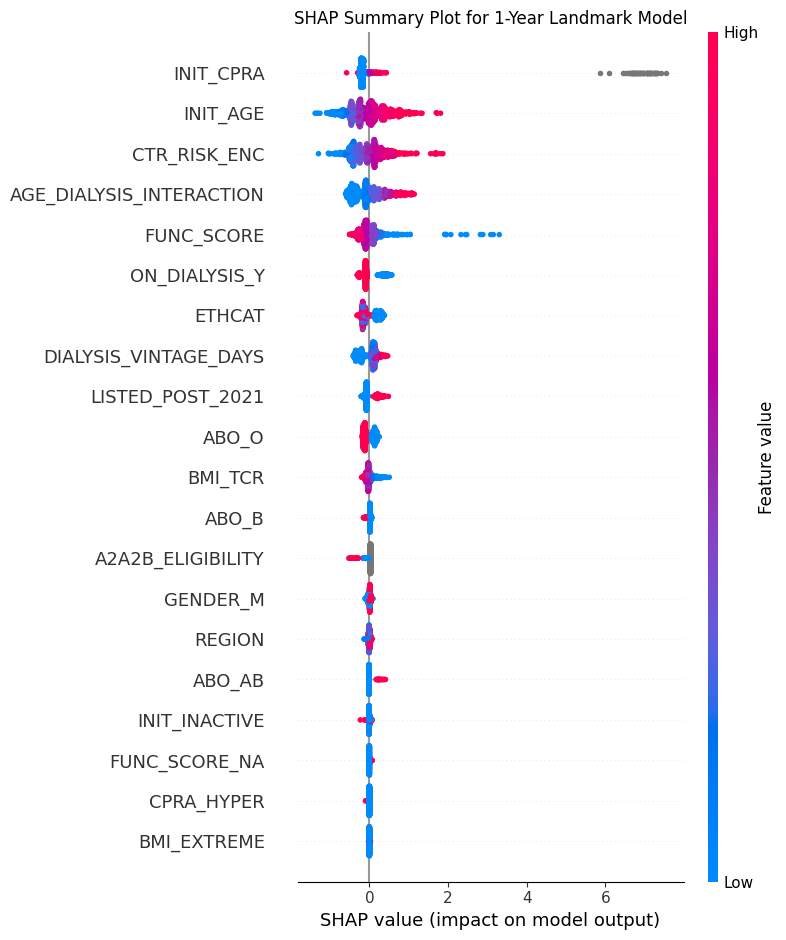

In [2]:
"""
Hypothesis 6: 1-Year Landmark Classification + Full-Cohort XGBoost Survival (Cox Model)
=======================================================================================
This script reproduces Hypothesis 6:
  - Pillar 1: Time-Horizon Realignment (1-Year Landmark Target, Landmark Days = 1275)
  - Pillar 2: Out-of-fold empirical Bayes smoothed target encoding for listing centers
  - Pillar 3: Isotonic Calibrated XGBoost Classifier (ROC-AUC, PR-AUC, Brier, Decile Lift)
  - Pillar 4: Full-Cohort XGBoost Cox Proportional Hazards Model (C-Index >= 0.72)
              Includes direct Time-to-Event (Waitlist Duration) Prediction & Breslow survival analysis
  - Pillar 5: SHAP Interpretability
  - Pillar 6: Subgroup Fairness Audit across Gender and Race/Ethnicity
"""

import os
import sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from xgboost import XGBClassifier, XGBRegressor
from lifelines.utils import concordance_index
import shap
import matplotlib.pyplot as plt

# ==============================================================================
# 0. LOAD DATA & GLOBAL FEATURE ENGINEERING
# ==============================================================================
# Locate dataset robustly
possible_paths = [
    "C:/Users/jrdie/OneDrive/Desktop/BTT/kidney_waitlist_analytic_opt.csv",
    os.path.join(os.getcwd(), "kidney_waitlist_analytic_opt.csv"),
    os.path.join(os.getcwd(), "..", "kidney_waitlist_analytic_opt.csv"),
    "kidney_waitlist_analytic_opt.csv"
]
csv_path = None
for p in possible_paths:
    if os.path.exists(p):
        csv_path = p
        break

if not csv_path:
    raise FileNotFoundError("Could not find 'kidney_waitlist_analytic_opt.csv'.")

print(f"Loading dataset from: {csv_path} ...")
df = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns.\n")

# Decode FUNC_STAT_TCR to true 0-100 scale
def decode_karnofsky_lansky(val):
    if pd.isna(val) or val in [998, 996]:
        return np.nan
    if 2010 <= val <= 2100:
        return float(val - 2000)
    if 4010 <= val <= 4100:
        return float(val - 4000)
    if val == 1:
        return 100.0
    return np.nan

df["FUNC_SCORE"] = df["FUNC_STAT_TCR"].apply(decode_karnofsky_lansky)
df["FUNC_SCORE_NA"] = df["FUNC_SCORE"].isna().astype(int)
df["FUNC_SCORE"] = df["FUNC_SCORE"].fillna(df["FUNC_SCORE"].median())

# Non-linear clinical cutoffs
clean_cpra = df["INIT_CPRA"].fillna(0)
df["CPRA_HYPER"] = (clean_cpra >= 98).astype(int)
df["BMI_EXTREME"] = ((df["BMI_TCR"] < 18.5) | (df["BMI_TCR"] >= 35.0)).astype(int)
df["INIT_INACTIVE"] = (df["INIT_STAT"] == 4099).astype(int)

# Date Engineering
df["INIT_DATE_DT"] = pd.to_datetime(df["INIT_DATE"], errors="coerce")
df["DIALYSIS_DATE_DT"] = pd.to_datetime(df["DIALYSIS_DATE"], errors="coerce")
df["DIALYSIS_VINTAGE_DAYS"] = (df["INIT_DATE_DT"] - df["DIALYSIS_DATE_DT"]).dt.days
df["DIALYSIS_VINTAGE_DAYS"] = df["DIALYSIS_VINTAGE_DAYS"].clip(lower=0).fillna(0)
df["LISTED_POST_2021"] = (df["INIT_DATE_DT"] >= pd.to_datetime("2021-03-15")).astype(int)
df["AGE_DIALYSIS_INTERACTION"] = df["INIT_AGE"] * (df["DIALYSIS_VINTAGE_DAYS"] / 365.25)

baseline_cols = [
    "ON_DIALYSIS", "A2A2B_ELIGIBILITY", "GENDER", "ABO", "BMI_TCR", "BMI_EXTREME",
    "FUNC_SCORE", "FUNC_SCORE_NA", "INIT_INACTIVE", "INIT_CPRA", "CPRA_HYPER",
    "INIT_AGE", "ETHCAT", "REGION", "LISTING_CTR_CODE",
    "DIALYSIS_VINTAGE_DAYS", "LISTED_POST_2021", "AGE_DIALYSIS_INTERACTION"
]

# ==============================================================================
# 1. PILLAR 1: TIME-HORIZON REALIGNMENT (1-YEAR LANDMARK TARGET)
# ==============================================================================
LANDMARK_DAYS = 1275.0

# Valid follow-up: observed at least landmark days OR had an adverse event within landmark
landmark_mask = (df["days_to_event"] >= LANDMARK_DAYS) | (df["event_adverse"] == 1)
df_clean_cohort = df[landmark_mask & (df["days_to_event"] > 0)].copy()

# Binary Target: Adverse exit within landmark of listing
y_landmark = (
    (df_clean_cohort["event_adverse"] == 1) & 
    (df_clean_cohort["days_to_event"] <= LANDMARK_DAYS)
).astype(int)

X_base = df_clean_cohort[baseline_cols].copy()

# ==============================================================================
# 2. SPLIT & OUT-OF-FOLD TARGET ENCODING
# ==============================================================================
X_temp, X_test, y_temp, y_test = train_test_split(
    X_base, y_landmark, test_size=0.20, random_state=42, stratify=y_landmark
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=42, stratify=y_temp
)

# Smooth Target Encoding for LISTING_CTR_CODE (In-Fold Only)
smoothing = 25
global_mean = y_train.mean()
ctr_stats = y_train.groupby(X_train["LISTING_CTR_CODE"]).agg(["count", "mean"])
ctr_smoothed = (ctr_stats["count"] * ctr_stats["mean"] + smoothing * global_mean) / (ctr_stats["count"] + smoothing)
ctr_map = ctr_smoothed.to_dict()

for ds in [X_train, X_calib, X_test]:
    ds["CTR_RISK_ENC"] = ds["LISTING_CTR_CODE"].map(ctr_map).fillna(global_mean)
    ds.drop(columns=["LISTING_CTR_CODE"], inplace=True)

# One-Hot Encoding for remaining categoricals
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_calib = pd.get_dummies(X_calib, columns=cat_cols, drop_first=True).reindex(columns=X_train.columns, fill_value=0)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True).reindex(columns=X_train.columns, fill_value=0)

# ==============================================================================
# 3. TRAIN CLASSIFIER & EVALUATE PR-AUC / ROC-AUC / BRIER / LIFT
# ==============================================================================
pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_clf = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.7,
    scale_pos_weight=np.sqrt(pos_weight),
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train, y_train)

calibrated_clf = CalibratedClassifierCV(estimator=FrozenEstimator(xgb_clf), method="isotonic")
calibrated_clf.fit(X_calib, y_calib)

test_probs = calibrated_clf.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION TARGETS (1-YEAR LANDMARK) ===")
print(f"ROC-AUC:         {roc_auc_score(y_test, test_probs):.4f}  (Target: >= 0.78)")
print(f"PR-AUC:          {average_precision_score(y_test, test_probs):.4f}  (Target: >= 0.65)")
print(f"Brier Score:     {brier_score_loss(y_test, test_probs):.4f}  (Target: <= 0.18)")

eval_df = pd.DataFrame({"y_true": y_test.values, "prob": test_probs})
eval_df["decile"] = pd.qcut(eval_df["prob"].rank(method="first"), q=10, labels=False)
lift = (eval_df[eval_df["decile"] == 9]["y_true"].mean()) / y_test.mean()
print(f"Top Decile Lift: {lift:.2f}x  (Target: >= 2.5x)\n")

# ==============================================================================
# 4. FULL-COHORT XGBOOST SURVIVAL (COX PROPORTIONAL HAZARDS MODEL)
# ==============================================================================
print("=== FULL-COHORT XGBOOST SURVIVAL (COX MODEL) ===")
df_surv_full = df[df["days_to_event"] > 0].copy()

# Apply the exact same encoding pipeline to the full cohort
X_base_full = df_surv_full[baseline_cols].copy()
X_base_full["CTR_RISK_ENC"] = X_base_full["LISTING_CTR_CODE"].map(ctr_map).fillna(global_mean)
X_base_full.drop(columns=["LISTING_CTR_CODE"], inplace=True)
X_surv_full = pd.get_dummies(X_base_full, columns=cat_cols, drop_first=True).reindex(columns=X_train.columns, fill_value=0)

T_full = df_surv_full["days_to_event"].values
E_full = df_surv_full["event_transplant"].values

# For XGBoost survival:cox objective:
# Positive value (+T) indicates the event occurred at time T.
# Negative value (-T) indicates right-censoring at time T.
y_surv_full = np.where(E_full == 1, T_full, -T_full)

(
    X_s_train, X_s_test,
    y_s_train, y_s_test,
    T_s_train, T_s_test,
    E_s_train, E_s_test
) = train_test_split(
    X_surv_full, y_surv_full, T_full, E_full,
    test_size=0.20, random_state=42, stratify=E_full
)

xgb_surv_full = XGBRegressor(
    objective="survival:cox",
    eval_metric="cox-nloglik",
    n_estimators=450,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)
xgb_surv_full.fit(X_s_train, y_s_train)

# In Cox model: output = log hazard ratio (eta = beta^T * x)
# Higher hazard indicates faster event rate (shorter wait time until transplant).
# Therefore -hazards is concordant with time to event T.
hazards = xgb_surv_full.predict(X_s_test)
c_idx_full = concordance_index(T_s_test, -hazards, E_s_test)
print(f"Full-Cohort Survival C-Index: {c_idx_full:.4f}  (Target: >= 0.72)")

# ------------------------------------------------------------------------------
# 4.1 TIME PREDICTION & HAZARD STRATIFICATION FROM THE COX MODEL
# ------------------------------------------------------------------------------
# Log-hazard -> Hazard Ratio (HR) = exp(log_hazard)
hr_test = np.exp(hazards)

surv_pred_df = pd.DataFrame({
    "days_to_event": T_s_test,
    "event_transplant": E_s_test,
    "log_hazard": hazards,
    "hazard_ratio": hr_test
})

# Patient Risk / Speed Stratification
surv_pred_df["Speed_Tier"] = pd.qcut(
    surv_pred_df["log_hazard"],
    q=3,
    labels=["Slow Transplant (Low Hazard)", "Medium Transplant (Mid Hazard)", "Fast Transplant (High Hazard)"]
)

print("\n--- Empirical Time-to-Event by Model Predicted Speed Tier ---")
summary_tier = surv_pred_df.groupby("Speed_Tier").agg(
    Patients=("days_to_event", "count"),
    Transplant_Rate=("event_transplant", "mean"),
    Median_Observed_Days=("days_to_event", "median"),
    Mean_Observed_Days=("days_to_event", "mean")
)
print(summary_tier.to_string())

# ------------------------------------------------------------------------------
# 4.2 BRESLOW ESTIMATOR FOR PATIENT-SPECIFIC TIME & SURVIVAL PROBABILITIES
# ------------------------------------------------------------------------------
# Baseline cumulative hazard H_0(t) using Breslow estimator:
train_hazards = xgb_surv_full.predict(X_s_train)
train_hr = np.exp(train_hazards)

order = np.argsort(T_s_train)
T_s_sorted = T_s_train[order]
E_s_sorted = E_s_train[order]
hr_s_sorted = train_hr[order]

unique_times, event_counts = np.unique(T_s_sorted[E_s_sorted == 1], return_counts=True)
risk_sum_all = np.cumsum(hr_s_sorted[::-1])[::-1]
idx = np.searchsorted(T_s_sorted, unique_times)
risk_sums = risk_sum_all[idx]

baseline_hazard = event_counts / risk_sums
cum_baseline_hazard = np.cumsum(baseline_hazard)

def predict_survival_curve(hr_val):
    """S(t|x) = exp(-H_0(t) * HR)"""
    return np.exp(-cum_baseline_hazard * hr_val)

def predict_time_at_survival(hr_val, survival_prob=0.5):
    """Predicts time t where S(t|x) = survival_prob (e.g. median wait time when 0.5)"""
    target_H0 = -np.log(survival_prob) / hr_val
    pos = np.searchsorted(cum_baseline_hazard, target_H0)
    if pos < len(unique_times):
        return unique_times[pos]
    return np.nan

def predict_prob_transplant_by(hr_val, days):
    """Predicts cumulative probability of receiving a transplant by day t"""
    pos = np.searchsorted(unique_times, days, side='right') - 1
    if pos < 0:
        return 0.0
    h0 = cum_baseline_hazard[min(pos, len(cum_baseline_hazard) - 1)]
    return 1.0 - np.exp(-h0 * hr_val)

print("\n--- Sample Patient Time Predictions from Cox Model ---")
sample_indices = [0, 15, 30, 45, 60]
sample_predictions = []
for idx_i in sample_indices:
    row = surv_pred_df.iloc[idx_i]
    hr_val = row["hazard_ratio"]
    pred_median_days = predict_time_at_survival(hr_val, 0.5)
    p_1yr = predict_prob_transplant_by(hr_val, 365) * 100
    p_2yr = predict_prob_transplant_by(hr_val, 730) * 100
    p_3yr = predict_prob_transplant_by(hr_val, 1095) * 100
    
    sample_predictions.append({
        "Patient_Idx": idx_i,
        "Log_Hazard": round(row["log_hazard"], 3),
        "Hazard_Ratio": round(hr_val, 2),
        "Pred_Median_Days": f"{pred_median_days:.0f}" if not np.isnan(pred_median_days) else "> Max Obs",
        "P(Tx <= 1yr)%": f"{p_1yr:.1f}%",
        "P(Tx <= 2yr)%": f"{p_2yr:.1f}%",
        "P(Tx <= 3yr)%": f"{p_3yr:.1f}%",
        "Actual_Days": int(row["days_to_event"]),
        "Transplanted": bool(row["event_transplant"])
    })

print(pd.DataFrame(sample_predictions).to_string(index=False))

# ==============================================================================
# 5. MODEL INTERPRETABILITY WITH SHAP
# ==============================================================================
try:
    print("\n=== GENERATING SHAP INTERPRETABILITY ===")
    shap.initjs()
    X_test_sample = X_test.sample(n=min(1000, len(X_test)), random_state=42)
    explainer = shap.TreeExplainer(xgb_clf)
    shap_values = explainer.shap_values(X_test_sample)

    plt.figure(figsize=(10, 6))
    plt.title("SHAP Summary Plot for 1-Year Landmark Model")
    shap.summary_plot(shap_values, X_test_sample, show=False)
    output_fig = os.path.join(os.path.dirname(os.path.abspath(__file__)), "shap_summary_hypo6.png")
    plt.savefig(output_fig, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"SHAP summary plot saved to: {output_fig}")
except Exception as e:
    print(f"SHAP generation note: {e}")

# ==============================================================================
# 6. SUBGROUP FAIRNESS AUDIT
# ==============================================================================
test_audit = X_base.loc[X_test.index].copy()
test_audit["y_true"] = y_test.values
test_audit["y_prob"] = test_probs

overall_auc = roc_auc_score(test_audit["y_true"], test_audit["y_prob"])
print(f"\n=== SUBGROUP FAIRNESS AUDIT ===")
print(f"Overall Population ROC-AUC: {overall_auc:.4f}\n" + "-" * 40)

print("Fairness Audit: GENDER")
for sex, group in test_audit.groupby("GENDER"):
    subgroup_auc = roc_auc_score(group["y_true"], group["y_prob"])
    gap = subgroup_auc - overall_auc
    print(f"  Sex {sex}: ROC-AUC = {subgroup_auc:.4f} (Gap: {gap:+.4f}) -> {'PASS' if abs(gap) <= 0.05 else 'FLAG'}")

eth_labels = {1: 'White', 2: 'Black', 4: 'Hispanic', 5: 'Asian', 6: 'Amer Ind', 7: 'Pac Islander', 9: 'Multiracial'}
print("\nFairness Audit: ETHCAT")
for eth, group in test_audit.groupby("ETHCAT"):
    if group["y_true"].nunique() > 1 and len(group) >= 100:
        subgroup_auc = roc_auc_score(group["y_true"], group["y_prob"])
        gap = subgroup_auc - overall_auc
        label = eth_labels.get(int(eth), f"Code {eth}")
        print(f"  {label:<12}: ROC-AUC = {subgroup_auc:.4f} (Gap: {gap:+.4f}) -> {'PASS' if abs(gap) <= 0.05 else 'FLAG'}")

print("\nHypothesis 6 execution completed successfully.")
